In [1]:
## Python Stuff
import os
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt


In [2]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F
import ctypes
import copy

ROOT.gErrorIgnoreLevel = ROOT.kFatal

ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()

Welcome to JupyROOT 6.27/01


In [3]:
## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

In [4]:

## ------------- User Inputs ------------- ##
## USER INPUTS (kinda bad ngl) ##
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
# QVAR_USE = "qRCFlat"
# QVAR_USE = "qRCFixed"
QVAR_USE = "qFlat"
# QVAR_USE = "qFixed"
PECUTVALUE = 0.5

## Paths to files, runLists
defPath = str(os.environ["CF4HOME"])+"/procData/" # where to get everything
bkgRunPath = "runLists/analysis1/bkgLists/"       # bkg run list files

In [5]:
## -------- physics and bkg runs -------- ##
runID_cs_bare_heights = [202203101341, 202203101306, 202203101150, 202203101534, 202203101506]
cs_bare_heights = [26.5, 28,	30.5,	32,	34.5]

runID_cs_LP_heights = [202204111600,	202204111454,	202204111423]
cs_LP_heights = [26, 28.5,	30.5]

physicsList = runID_cs_bare_heights + runID_cs_LP_heights

# bkg runs
bkgList_0310 = np.loadtxt(defPath + bkgRunPath+ "date_0310-48V.txt", dtype=int).tolist()
bkgList_0411 = np.loadtxt(defPath + bkgRunPath+ "date_0411-48V.txt", dtype=int).tolist()

# final inputs into code
allBkgs = bkgList_0310 + bkgList_0411
allRuns = allBkgs + physicsList

In [6]:
## Get all RC objects ##
rcList = [] ## everything from here
fList = []

speList = []
chi2list = []

# loading data and SPE analysis
# everything is in rcList
for run in allRuns:
  f = ROOT.TFile(defPath + "analysis1/npv1_" + str(run) + ".root", "READ") #file opens
  fList.append(f) # NEED THIS to keep ttrees persistent (all reference in Python)

  tt = f.Get("tt")
  rcObj = RunClass(run, tt)

  rcObj.assign_height(runID_cs_bare_heights, cs_bare_heights)
  rcObj.assign_height(runID_cs_LP_heights, cs_LP_heights)

  rcObj.computeSPE(width = 15, verbose=VERBOSE, varname=QVAR_USE, channels = [i for i in range(NCHAN)])
  rcList.append(rcObj)

  for chan in rcObj.mChannels:
    # print(chan.mSpe.chi2)
    speList.append(chan.mSpe.spe)
    chi2list.append(chan.mSpe.chi2)

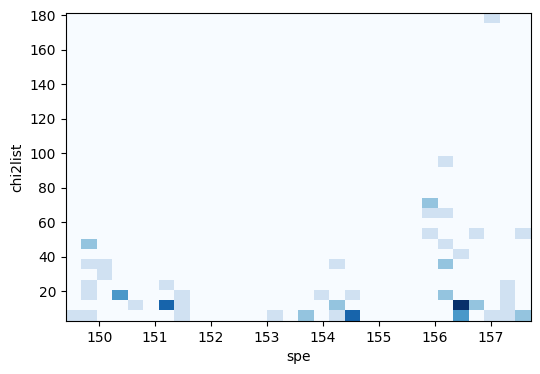

In [7]:
## checking spe and chi2 values
plt.figure(figsize=(6, 4))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.xlabel("spe")
plt.ylabel("chi2list")
plt.show()

In [8]:
# printing information
# rcList[0].tt.Show(0)
# for rc in rcList:
#   rc.print()

#### Sorting RC objects ####
rcl_Bkg_0310 = SORTING.pickListOfRC(bkgList_0310, rcList) # get all RC background objects
rcl_cs_bare_heights = SORTING.pickListOfRC(runID_cs_bare_heights, rcList)

rcl_Bkg_0411 = SORTING.pickListOfRC(bkgList_0411, rcList) # get all RC background objects
rcl_cs_lp_heights = SORTING.pickListOfRC(runID_cs_LP_heights, rcList)

######## Building Full Spectra ########
binHigh = 80.
Nbins = 400.
binWidth = (binHigh - 0.) / Nbins
hReference = TH1F("hReference", "hReference", int(Nbins), 0., binHigh) # histogram that everything is built off
hReference.Sumw2(True)

# building all SPE spectra
for rc in rcList:
  rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate = True)

# building averaged bkg spectra
hNPE_bkg_0310 = hReference.Clone("hNPE_bkg_0310") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0310, QVAR_USE, hNPE_bkg_0310, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

hNPE_bkg_0411 = hReference.Clone("hNPE_bkg_0411") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0411, QVAR_USE, hNPE_bkg_0411, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

## Time between events for one run
hTimeBetweenEvents = TH1F("hTimeBetweenEvents", "hTimeBetweenEvents", 100, 0., 0.2)
for rc in rcl_Bkg_0310:
  rc.BuildTTNE(hTimeBetweenEvents)
  
# for rc in rcl_cs_bare_heights:
#   rc.BuildCorrSpectrum(hNPE_bkg_0310)

# for rc in rcl_cs_lp_heights:
#   rc.BuildCorrSpectrum(hNPE_bkg_0411)

done filling histogram: hNPE_202203101136
done filling histogram: hNPE_202203101245
done filling histogram: hNPE_202203101333
done filling histogram: hNPE_202203101424
done filling histogram: hNPE_202203101457
done filling histogram: hNPE_202203101526
done filling histogram: hNPE_202203101553
done filling histogram: hNPE_202204111213
done filling histogram: hNPE_202204111229
done filling histogram: hNPE_202204111247
done filling histogram: hNPE_202204111323
done filling histogram: hNPE_202204111434
done filling histogram: hNPE_202204111520
done filling histogram: hNPE_202204111623
done filling histogram: hNPE_202203101341
done filling histogram: hNPE_202203101306
done filling histogram: hNPE_202203101150
done filling histogram: hNPE_202203101534
done filling histogram: hNPE_202203101506
done filling histogram: hNPE_202204111600
done filling histogram: hNPE_202204111454
done filling histogram: hNPE_202204111423
done building fast bkg histogram for hNPE_bkg_0310
total time: 3025.23816213

In [9]:
c0 = TCanvas()
c0.Divide(1, 2, 0.01, 0.01, 0)
c0.SetLogy()

hReference.GetXaxis().SetRangeUser(0, 20)
hReference.Draw("hist")

for rc in rcl_Bkg_0310:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0310.index(rc)+1)
  h.SetLineWidth(3)

  h.Draw("hist same E")

  c0.cd(2)
  c0.cd(2).SetLogy()
  hReference.Draw("hist")

for rc in rcl_Bkg_0411:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0411.index(rc)+1)
  h.SetLineWidth(2)

  h.Draw("hist same E")

c0.Update()
c0.Draw()


In [10]:
#### TTNE figs ####
c2 = TCanvas()
# hTimeBetweenEvents.GetXaxis().SetLimits(0.1, 1000)
hTimeBetweenEvents.SetMaximum(1000)
hTimeBetweenEvents.Draw("hist")

for rc in rcl_Bkg_0310:
  h = rc.mhTTNE
  index = rcl_Bkg_0310.index(rc)
  h.SetLineColor(index+1)
  h.SetLineWidth(2)
  h.Scale(1+index/10.)
  h.Draw("hist same E")

c2.SetLogy()
c2.Update()
c2.Draw()

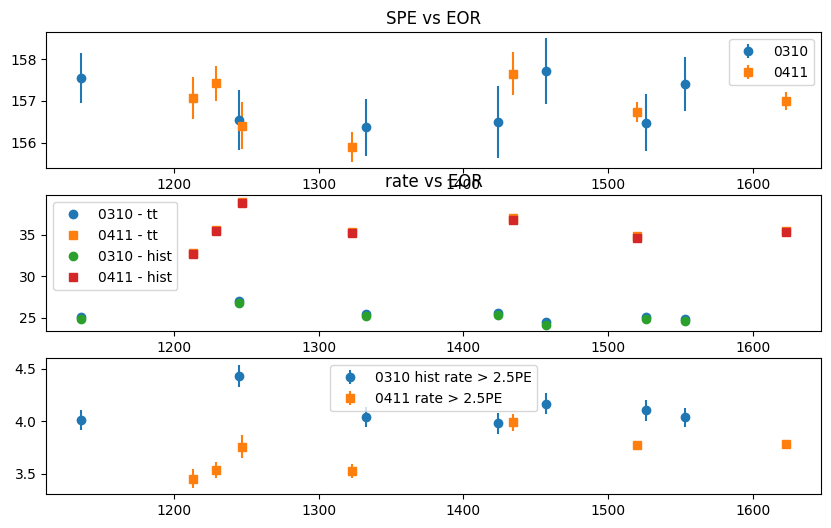

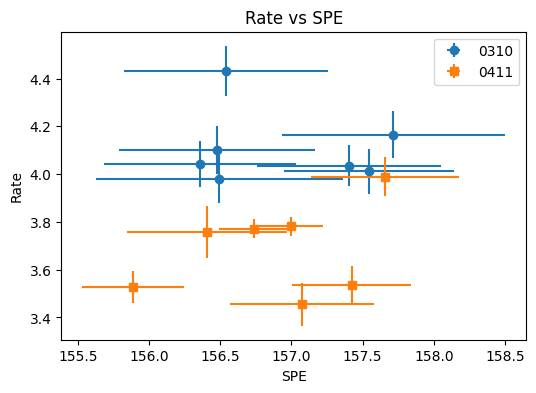

In [12]:
################ Matplotlib Math ################
### Bkg investigation ###

## SPE size ##
plotChan = 2
ySPE_0310 = np.array([rc.GetSPE(plotChan) for rc in rcl_Bkg_0310])
yeSPE_0310 = np.array([rc.GetChan(plotChan).mSpe.espe for rc in rcl_Bkg_0310])
xEOR_0310 = np.array([int(rc.GetEORtime()) for rc in rcl_Bkg_0310])

ySPE_0411 = np.array([rc.GetSPE(plotChan) for rc in rcl_Bkg_0411])
yeSPE_0411 = np.array([rc.GetChan(plotChan).mSpe.espe for rc in rcl_Bkg_0411])
xEOR_0411 = np.array([int(rc.GetEORtime()) for rc in rcl_Bkg_0411])

## TT rate ##
yTTrate_0310 = np.array([rc.GetRate() for rc in rcl_Bkg_0310])
yeTTrate_0310 = np.array([rc.mRateError for rc in rcl_Bkg_0310])

yTTrate_0411 = np.array([rc.GetRate() for rc in rcl_Bkg_0411])
yeTTrate_0411 = np.array([rc.mRateError for rc in rcl_Bkg_0411])

## histogram full rate ##
yHistRate_0310 = np.array([rc.GetSpectrum().Integral() for rc in rcl_Bkg_0310])
yHistRate_0411 = np.array([rc.GetSpectrum().Integral() for rc in rcl_Bkg_0411])

## 2PE and above rates ##
lowPE = 2.5
ey = ctypes.c_double()
yHistRate2_0310 = []
for rc in rcl_Bkg_0310:
  integ = rc.GetSpectrum().IntegralAndError(int(lowPE/binWidth), int(20./binWidth), ey)
  yHistRate2_0310.append([integ, copy.copy((float(ey.value)))])
yHistRate2_0310 = np.array(yHistRate2_0310)

yHistRate2_0411 = []
for rc in rcl_Bkg_0411:
  integ = rc.GetSpectrum().IntegralAndError(int(lowPE/binWidth), int(20./binWidth), ey)
  yHistRate2_0411.append([integ, copy.copy((float(ey.value)))])
yHistRate2_0411 = np.array(yHistRate2_0411)

# yHistRate2_0310 = np.array([rc.GetSpectrum().Integral(int(2.5/binWidth), int(20./binWidth)) for rc in rcl_Bkg_0310])
# yHistRate2_0411 = np.array([rc.GetSpectrum().Integral(int(2.5/binWidth), int(20./binWidth)) for rc in rcl_Bkg_0411])

##### Rate, SPE vs EOR #####
plt.ion()
bkgfig, bkgaxes = plt.subplots(3, 1, figsize = (10, 6))

bkgaxes[0].errorbar(x = xEOR_0310, y = ySPE_0310, yerr = yeSPE_0310, label = "0310", marker = "o", linestyle = 'None')
bkgaxes[0].errorbar(x = xEOR_0411, y = ySPE_0411, yerr = yeSPE_0411, label = "0411", marker = "s", linestyle = 'None')

bkgaxes[0].set_title("SPE vs EOR")
bkgaxes[0].legend()

bkgaxes[1].plot(xEOR_0310, yTTrate_0310, marker = "o", linestyle = 'None', label = "0310 - tt")
bkgaxes[1].plot(xEOR_0411, yTTrate_0411, marker = "s", linestyle = 'None', label = "0411 - tt")

bkgaxes[1].plot(xEOR_0310, yHistRate_0310, marker = "o", linestyle = 'None', label = "0310 - hist")
bkgaxes[1].plot(xEOR_0411, yHistRate_0411, marker = "s", linestyle = 'None', label = "0411 - hist")

bkgaxes[1].set_title("rate vs EOR")
bkgaxes[1].legend()

bkgaxes[2].errorbar(xEOR_0310, yHistRate2_0310[:,0], yerr = yHistRate2_0310[:, 1], marker = "o", linestyle = 'None', label="0310 hist rate > 2.5PE")
bkgaxes[2].errorbar(xEOR_0411, yHistRate2_0411[:,0], yerr = yHistRate2_0411[:,1], marker = "s", linestyle = 'None', label="0411 rate > 2.5PE")
bkgaxes[2].legend()

##### SPE vs Rate plots #####
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.errorbar(x = ySPE_0310, y = yHistRate2_0310[:, 0], xerr = yeSPE_0310, yerr = yHistRate2_0310[:, 1], marker = "o", linestyle = 'None', label = "0310")
ax.errorbar(x = ySPE_0411, y = yHistRate2_0411[:,0], xerr = yeSPE_0411, yerr = yHistRate2_0411[:,1], marker = "s", linestyle = 'None', label = "0411")

ax.legend()
ax.set_xlabel("SPE")
ax.set_ylabel("Rate")
ax.set_title("Rate vs SPE")

plt.show()
